In [5]:
import os
import random
import shutil
from glob import glob


In [6]:
patches_dir = "../preprocessed/patches"         # Where all patches are
balanced_dir = "../preprocessed/balanced_patches"  # New folder for balanced dataset
os.makedirs(balanced_dir, exist_ok=True)


In [8]:
positive_files = [f for f in glob(os.path.join(patches_dir, "*.npz")) if '_label1.npz' in f]
negative_files = [f for f in glob(os.path.join(patches_dir, "*.npz")) if '_label0.npz' in f]

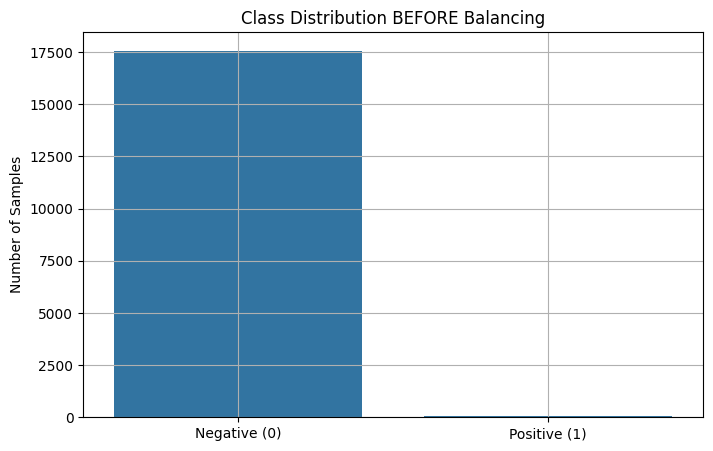

In [9]:
# 📊 Class Distribution BEFORE Balancing

import matplotlib.pyplot as plt
import seaborn as sns

counts_before = [len(negative_files), len(positive_files)]

plt.figure(figsize=(8, 5))
sns.barplot(x=["Negative (0)", "Positive (1)"], y=counts_before)
plt.title("Class Distribution BEFORE Balancing")
plt.ylabel("Number of Samples")
plt.grid(True)
plt.show()


Balancing Code

In [12]:
# List positive and negative patch files
positive_files = [f for f in glob(os.path.join(patches_dir, "*.npz")) if '_label1.npz' in f]
negative_files = [f for f in glob(os.path.join(patches_dir, "*.npz")) if '_label0.npz' in f]

print(f"📋 Found {len(positive_files)} positives and {len(negative_files)} negatives.")

# Randomly select negatives
target_negatives = 150  # you can adjust this number if needed
selected_negatives = random.sample(negative_files, target_negatives)

# Copy selected patches into new folder
for f in positive_files + selected_negatives:
    shutil.copy(f, balanced_dir)

print(f"\n✅ Balanced dataset created:")
print(f"- Positives: {len(positive_files)}")
print(f"- Negatives: {len(selected_negatives)}")
print(f"- Total patches: {len(positive_files) + len(selected_negatives)}")


📋 Found 46 positives and 17575 negatives.

✅ Balanced dataset created:
- Positives: 46
- Negatives: 150
- Total patches: 196


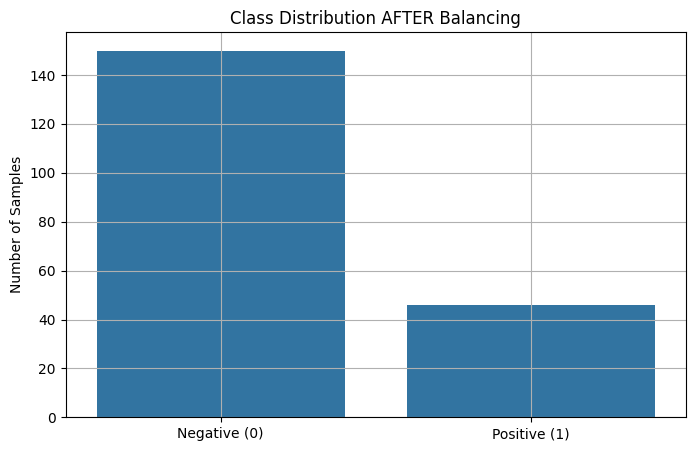

In [14]:
# 📊 Class Distribution AFTER Balancing

counts_after = [len(selected_negatives), len(positive_files)]

plt.figure(figsize=(8, 5))
sns.barplot(x=["Negative (0)", "Positive (1)"], y=counts_after)
plt.title("Class Distribution AFTER Balancing")
plt.ylabel("Number of Samples")
plt.grid(True)
plt.show()
